# Baseline-relative MRI cohort visualizations

## tl;dr
This notebook reads the saved patient split and describes one retained MRI per patient
per scheduled follow-up bin. Run `data_splitting.ipynb` first. The cohort summary below is
computed from the validated saved split; visualization does not regenerate assignments.

## Context & Methods
Sources: `_core.core_image_set`, `_core.core_follow_up_buckets`, `_core.core_ptdemog`, and
`_raw.train_test_split`; see the [image model](../mstat_project_dbt/models/core/core_image_set.sql)
and [schedule model](../mstat_project_dbt/models/core/core_follow_up_buckets.sql).
Use the repository Python environment (`uv sync`) and `.env` for database access.

### Key Assumptions
- BL is the patient's earliest eligible image. Visit codes identify **scheduled elapsed-time
  bins**, not consecutive observed scans. Missing bins are not renumbered or imputed.
- The schedule is loaded from dbt. BL is day zero; follow-up windows are lower-inclusive
  and upper-exclusive. The current `v1` includes positive times below nine months, and
  `v16` ends before 180 months. Target months are labels, not actual acquisition times.
- The cohort is the frozen tensor-file-eligible patient set. All retained images, including
  event-day images, contribute to descriptions; prediction models still apply `mri_is_valid`.
- Counts, gaps, and last diagnosis are recomputed from retained rows. SQL `n_ptid_imgs` and
  `final_diagnosis` are pre-filter fields and are not used as retained-cohort summaries.
- AD timing is the first retained selected-image date labeled AD, following the model's
  diagnosis intervals; it is not an independently adjudicated onset date. Histograms of
  observed AD times are descriptive, not censoring-adjusted survival estimates.

In [1]:
from pathlib import Path
import json
from datetime import datetime, timezone
import polars as pl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sqlalchemy
from IPython.display import display, Markdown
from dotenv import load_dotenv
from mstat_project.utils import get_db_engine
from mstat_project.data_prep.data_splitting import (
    PROPORTIONS, load_binned_cohort, tensor_eligible_images, patient_split_frame,
    weighted_patient_split, validate_assignments, frame_fingerprint, persist_splits,
)

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists())
load_dotenv(ROOT / '.env')
ARTIFACT_DIR = ROOT / 'data/artifacts/data_splits'
engine = get_db_engine()
pd.set_option('display.max_rows', 30)
pd.set_option('display.max_columns', 12)
SPLIT_ORDER = ['train', 'validation', 'test']
SPLIT_COLORS = {'train': '#0072B2', 'validation': '#D89000', 'test': '#8B5FA8'}

## Data
### Load saved assignments and detect stale inputs
The saved manifest must match both the current assignments and the selected cohort/schedule.
If a dbt rebuild changes them, rerun the splitting notebook deliberately before continuing.
The file-existence rule used at split time is recorded in the manifest, not reapplied here.

In [2]:
manifest_path = ARTIFACT_DIR / 'latest.json'
if not manifest_path.exists():
    raise FileNotFoundError('Run data_splitting.ipynb with WRITE_SPLITS=True first.')
manifest = json.loads(manifest_path.read_text(encoding='utf-8'))
all_images, buckets = load_binned_cohort(engine)
with engine.connect() as conn:
    assignments = pl.read_database('SELECT ptid, split FROM _raw.train_test_split', conn)
images = all_images.join(assignments.select('ptid'), on='ptid', how='semi')
validate_assignments(patient_split_frame(images), assignments)
for key, frame in [('cohort', images), ('buckets', buckets), ('assignments', assignments)]:
    if frame_fingerprint(frame) != manifest[f'{key}_sha256']:
        raise ValueError(f'{key} changed since split creation. Rerun data_splitting.ipynb.')
viz_df = images.join(assignments, on='ptid', validate='m:1')
display(Markdown(f"**Verified cohort:** {assignments.height:,} patients, {images.height:,} retained images; "
                 f"split snapshot `{manifest['created_at_utc']}`. "
                 f"Excluded from the split: {all_images['ptid'].n_unique() - assignments.height:,} "
                 "source patients without tensor files at split time."))
display(buckets.to_pandas())

**Verified cohort:** 2,636 patients, 8,027 retained images; split snapshot `20260926T202443358731Z`. Excluded from the split: 2 source patients without tensor files at split time.

,visit_num,visit_code,follow_up_months,follow_up_start,follow_up_end
0,0,BL,0,0.00,0.00
1,1,v1,6,0.00,9.00
2,2,v2,12,9.00,18.00
3,3,v3,24,18.00,30.00
4,4,v4,36,30.00,42.00
5,5,v5,48,42.00,54.00
6,6,v6,60,54.00,66.00
7,7,v7,72,66.00,78.00
8,8,v8,84,78.00,90.00
9,9,v9,96,90.00,102.00


### Prepare patient and image summaries
Categorical panels use within-split percentages. Patient mean error bars are approximate
95% normal confidence intervals (`mean ± 1.96 × SD / sqrt(n)`), using nonmissing patients.
Set `SAVE_FIGURES` or `SAVE_TABLES` to export PNG/PDF figures or CSV/HTML/LaTeX tables.

In [3]:
from pathlib import Path
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator, PercentFormatter
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

SPLIT_ORDER = ["train", "validation", "test"]
SPLIT_LABELS = {"train": "Train", "validation": "Validation", "test": "Test"}
SPLIT_COLORS = {"train": "#0072B2", "validation": "#E69F00", "test": "#8B5FA8"}
SAVE_FIGURES = False
FIGURE_DIR = ROOT / "reports/figures"

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
})

scan_df = viz_df.to_pandas().sort_values(['ptid', 'visit_num']).copy()
# Keep actual timing distinct from the scheduled target; recompute gaps after final filters.
scan_df['months_since_prior_image'] = (
    pd.to_datetime(scan_df['image_date']).groupby(scan_df['ptid']).diff().dt.days / 365 * 12
).fillna(0).round(2)
endpoint = scan_df.groupby('ptid', sort=False)['diagnosis_at_visit'].last()
scan_df['last_retained_diagnosis'] = scan_df['ptid'].map(endpoint)
scan_df['retained_diagnosis_change'] = np.where(
    scan_df['baseline_diagnosis'] == scan_df['last_retained_diagnosis'],
    'Stable - ' + scan_df['baseline_diagnosis'],
    'Conversion - ' + scan_df['baseline_diagnosis'] + ' to ' + scan_df['last_retained_diagnosis'],
)
patient_df = (
    scan_df.sort_values(["ptid", "image_date", "image_id"])
    .drop_duplicates("ptid", keep="first")
    .copy()
)
patient_df["sex"] = patient_df["pt_gender_code"].map({1: "Male", 2: "Female"}).fillna("Unknown")
patient_df["marital_status"] = patient_df["pt_marital_status"].map({
    1: "Married", 2: "Widowed", 3: "Divorced", 4: "Never married",
    5: "Unknown", 6: "Other",
}).fillna("Unknown")
patient_df["censor_status"] = np.where(patient_df["is_censored"], "Censored", "Observed AD")
patient_df["diagnosis_change"] = patient_df["retained_diagnosis_change"].replace({
    "Stable - CN": "Stable CN",
    "Stable - MCI": "Stable MCI",
    "Conversion - CN to MCI": "CN → MCI",
    "Conversion - CN to AD": "CN → AD",
    "Conversion - MCI to CN": "MCI → CN",
    "Conversion - MCI to AD": "MCI → AD",
})

visit_counts = (
    scan_df.groupby(["ptid", "split"], observed=True)["visit_code"]
    .nunique()
    .rename("n_visits")
    .reset_index()
)
patient_df = patient_df.drop(columns=["n_visits"], errors="ignore").merge(visit_counts, on=["ptid", "split"])

scan_df["manufacturer"] = (
    scan_df["mri_manufacturer"].astype("string").str.upper()
    .replace({"GE": "GE", "SIEMENS": "Siemens", "PHILIPS": "Philips", "OTHER": "Other"})
    .fillna("Unknown")
)
slice_numeric = pd.to_numeric(scan_df["slice_thickness"], errors="coerce")
scan_df["slice_thickness_group"] = slice_numeric.map(lambda value: f"{value:g} mm" if pd.notna(value) else "Unknown")
field_numeric = pd.to_numeric(
    scan_df["magnetic_field_strength"].astype("string").str.replace("T", "", regex=False),
    errors="coerce",
)
field_numeric = field_numeric.where(field_numeric <= 100, field_numeric / 10_000)
scan_df["field_strength"] = field_numeric.map(lambda value: f"{value:g} T" if pd.notna(value) else "Unknown")
scan_df["acceleration"] = scan_df["is_accelerated"].map({True: "Accelerated", False: "Not accelerated"}).fillna("Unknown")

SPLIT_LEGEND = [Patch(facecolor=SPLIT_COLORS[name], label=SPLIT_LABELS[name]) for name in SPLIT_ORDER]

def _style_axis(ax, percent=False):
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.grid(axis="y", color="#D9E1E8", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(axis="both", length=0)
    if percent:
        ax.yaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))

def _mean_bars(ax, data, column, title, ylabel):
    summary = data.groupby("split", observed=True)[column].agg(["mean", "std", "count"]).reindex(SPLIT_ORDER)
    ci95 = 1.96 * summary["std"] / np.sqrt(summary["count"])
    bars = ax.bar(
        np.arange(len(SPLIT_ORDER)), summary["mean"], yerr=ci95, capsize=4, width=0.68,
        color=[SPLIT_COLORS[name] for name in SPLIT_ORDER], edgecolor="white", linewidth=0.8,
    )
    ax.bar_label(bars, labels=[f"{value:.1f}" for value in summary["mean"]], padding=4, fontweight="bold")
    ax.set_xticks(np.arange(len(SPLIT_ORDER)), [SPLIT_LABELS[name] for name in SPLIT_ORDER])
    ax.set(title=title, ylabel=ylabel)
    ax.set_ylim(0, max(summary["mean"] + ci95) * 1.16)
    _style_axis(ax)

def _rate_bars(ax, data, column, title):
    rates = data.groupby("split", observed=True)[column].mean().reindex(SPLIT_ORDER).mul(100)
    bars = ax.bar(
        np.arange(len(SPLIT_ORDER)), rates, width=0.68,
        color=[SPLIT_COLORS[name] for name in SPLIT_ORDER], edgecolor="white", linewidth=0.8,
    )
    ax.bar_label(bars, labels=[f"{value:.1f}%" for value in rates], padding=4, fontweight="bold")
    ax.set_xticks(np.arange(len(SPLIT_ORDER)), [SPLIT_LABELS[name] for name in SPLIT_ORDER])
    ax.set(title=title, ylabel="Patients (%)")
    ax.set_ylim(0, min(100, max(rates) * 1.20))
    _style_axis(ax, percent=True)

def _grouped_percent_bars(ax, data, column, categories, title, unit="Patients", rotate=0):
    values = data[column].fillna("Unknown")
    table = pd.crosstab(values, data["split"], normalize="columns").mul(100)
    table = table.reindex(index=categories, columns=SPLIT_ORDER, fill_value=0)
    x = np.arange(len(categories))
    width = 0.24
    for index, split in enumerate(SPLIT_ORDER):
        heights = table[split].to_numpy()
        bars = ax.bar(x + (index - 1) * width, heights, width, color=SPLIT_COLORS[split], label=SPLIT_LABELS[split])
        labels = [f"{value:.0f}" if value >= 3 else "" for value in heights]
        ax.bar_label(bars, labels=labels, padding=2, fontsize=8)
    ax.set_xticks(x, categories, rotation=rotate, ha="right" if rotate else "center")
    ax.set(title=title, ylabel=f"{unit} (%)")
    ax.set_ylim(0, min(100, max(5, table.to_numpy().max()) * 1.22))
    _style_axis(ax, percent=True)

def _solid_histogram(ax, data, column, bins, split, title, xlabel, unit="Patients"):
    values = pd.to_numeric(data.loc[data["split"] == split, column], errors="coerce").dropna()
    if not values.empty:
        weights = np.full(len(values), 100 / len(values))
        ax.hist(
            values, bins=bins, weights=weights, histtype="bar",
            color=SPLIT_COLORS[split], alpha=0.9, edgecolor="white", linewidth=0.8,
        )
    ax.set(title=title, xlabel=xlabel, ylabel=f"{unit} per bin (%)")
    _style_axis(ax, percent=True)

def _finish_figure(fig, title, subtitle, filename, show_legend=True):
    fig.suptitle(title, x=0.01, y=0.995, ha="left", fontsize=18, fontweight="bold")
    fig.text(0.01, 0.958, subtitle, ha="left", va="top", fontsize=10, color="#52616B")
    if show_legend:
        fig.legend(handles=SPLIT_LEGEND, loc="upper right", bbox_to_anchor=(0.99, 0.995), frameon=False, ncol=3)
    fig.tight_layout(rect=(0, 0, 1, 0.90))
    if SAVE_FIGURES:
        FIGURE_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(FIGURE_DIR / f"{filename}.png", bbox_inches="tight", facecolor="white")
        fig.savefig(FIGURE_DIR / f"{filename}.pdf", bbox_inches="tight", facecolor="white")
    plt.show()

## Results
### Cohort size, events, and retained bins
Patients are counted once; images and valid prediction inputs are counted at patient/bin grain.

In [4]:
summary = patient_df.groupby('split').agg(
    patients=('ptid', 'size'), observed_ad=('is_censored', lambda s: int((~s).sum())),
    median_bins=('n_visits', 'median'), baseline_only=('n_visits', lambda s: int((s == 1).sum())),
).reindex(SPLIT_ORDER)
summary['images'] = scan_df.groupby('split').size()
summary['valid_prediction_images'] = scan_df.groupby('split')['mri_is_valid'].sum()
summary['event_pct'] = (100 * summary['observed_ad'] / summary['patients']).round(2)
display(summary)

,patients,observed_ad,median_bins,baseline_only,images,valid_prediction_images,event_pct
split,,,,,,,
train,1842,186,3.0,638,5621,5435,10.10
validation,397,41,3.0,136,1203,1162,10.33
test,397,41,3.0,136,1203,1162,10.33


### Scheduled-bin coverage
Each cell is the percentage of **all assigned patients in that split** with a retained image
in that bin. Counts include event images. A missing combination is zero observed images;
this is coverage, not a retention probability or a count of patients still at risk.

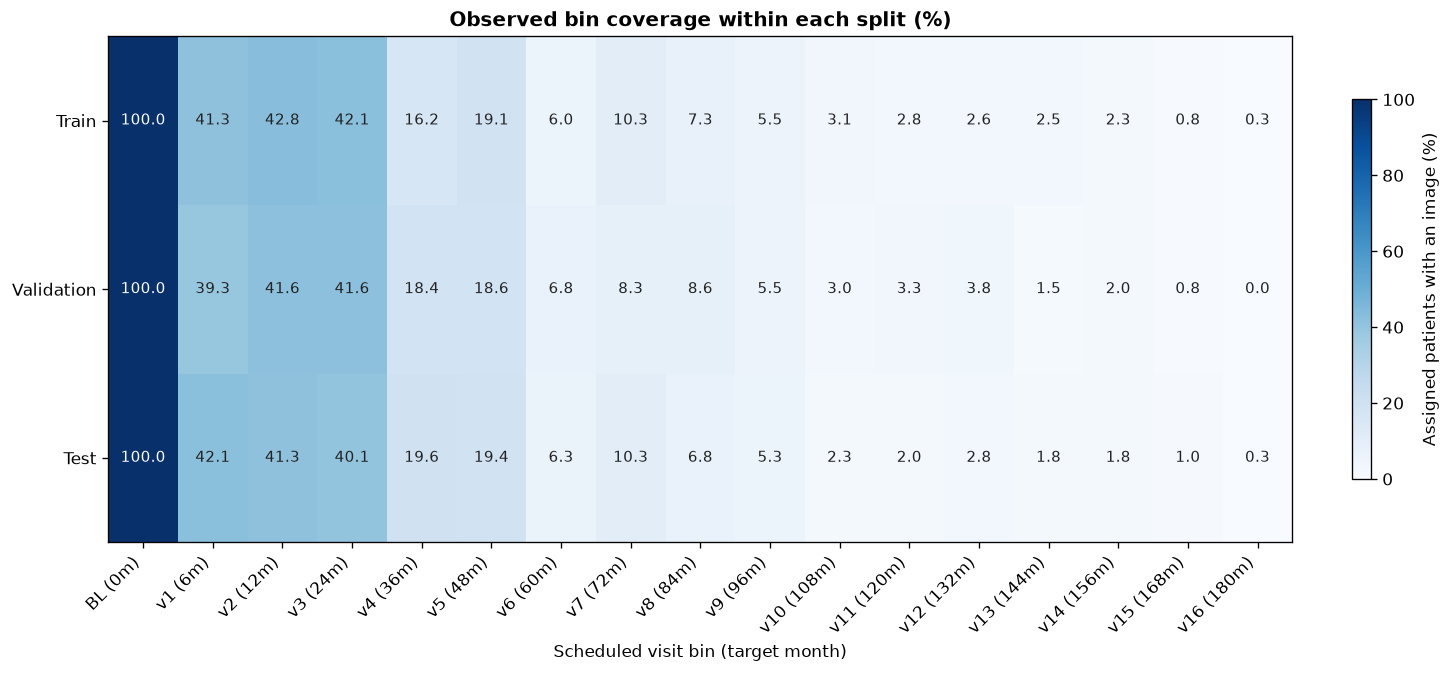

split,train,validation,test
Bin (target month),,,
BL (0m),1842,397,397
v1 (6m),760,156,167
v2 (12m),789,165,164
v3 (24m),775,165,159
v4 (36m),299,73,78
v5 (48m),352,74,77
v6 (60m),110,27,25
v7 (72m),190,33,41
v8 (84m),135,34,27


In [5]:
schedule = buckets.to_pandas().set_index('visit_num')
bin_counts = pd.crosstab(scan_df['visit_num'], scan_df['split']).reindex(
    index=schedule.index, columns=SPLIT_ORDER, fill_value=0)
coverage = bin_counts.div(summary['patients'], axis='columns').mul(100)
bin_labels = [f"{r.visit_code} ({r.follow_up_months:g}m)" for r in schedule.itertuples()]
fig, ax = plt.subplots(figsize=(12, 5.5), layout='constrained')
heat = ax.imshow(coverage.T, aspect='auto', cmap='Blues', vmin=0, vmax=100)
for y, split_name in enumerate(SPLIT_ORDER):
    for x, pct in enumerate(coverage[split_name]):
        ax.text(x, y, f'{pct:.1f}', ha='center', va='center', fontsize=9,
                color='white' if pct >= 55 else '#222222')
ax.set(xticks=np.arange(len(schedule)), xticklabels=bin_labels,
       yticks=np.arange(3), yticklabels=[s.title() for s in SPLIT_ORDER],
       xlabel='Scheduled visit bin (target month)', title='Observed bin coverage within each split (%)')
plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
fig.colorbar(heat, ax=ax, label='Assigned patients with an image (%)', shrink=0.75)
if SAVE_FIGURES:
    FIGURE_DIR.mkdir(parents=True, exist_ok=True)
    for extension in ['png', 'pdf']:
        fig.savefig(FIGURE_DIR / f'follow_up_bin_coverage.{extension}', bbox_inches='tight')
plt.show()
display(bin_counts.set_axis(bin_labels).rename_axis('Bin (target month)'))

### Actual imaging time relative to the target
Boxes show median and IQR, whiskers extend to 1.5 IQR, and points show more extreme offsets.
All assigned images contribute; repeated images from a patient are descriptive observations,
not independent statistical replicates. BL is exactly zero and is omitted from the offsets.

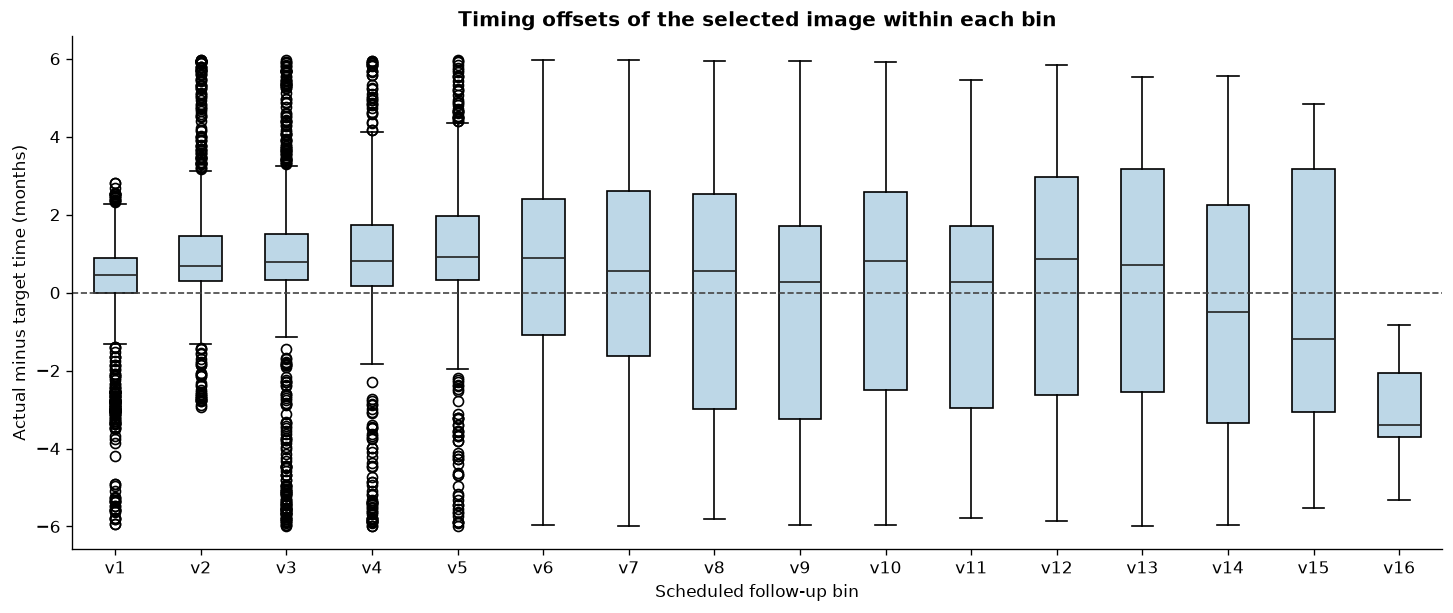

,visit_code,follow_up_months,images,min_months,median_months,max_months,median_offset_months
visit_num,,,,,,,
0,BL,0,2636,0.00,0.0,0.00,0.00
1,v1,6,1083,0.07,6.44,8.81,0.44
2,v2,12,1118,9.07,12.69,17.98,0.69
3,v3,24,1099,18.02,24.79,29.98,0.79
4,v4,36,450,30.02,36.805,41.95,0.80
5,v5,48,503,42.02,48.92,53.98,0.92
6,v6,60,162,54.05,60.89,65.98,0.89
7,v7,72,264,66.02,72.545,77.98,0.55
8,v8,84,196,78.18,84.555,89.95,0.55


In [6]:
timing = scan_df.merge(schedule.reset_index(), on=['visit_num', 'visit_code'], validate='many_to_one')
timing['offset_months'] = pd.to_numeric(timing['months_since_baseline_image']) - pd.to_numeric(timing['follow_up_months'])
follow_schedule = schedule.loc[schedule['visit_code'] != 'BL']
offsets = [timing.loc[timing['visit_num'] == n, 'offset_months'].astype(float).to_numpy() for n in follow_schedule.index]
fig, ax = plt.subplots(figsize=(12, 5), layout='constrained')
ax.boxplot(offsets, tick_labels=follow_schedule['visit_code'], patch_artist=True,
           boxprops={'facecolor': '#BDD7E7'}, medianprops={'color': '#222222'})
ax.axhline(0, color='#444444', linestyle='--', linewidth=1)
ax.set(xlabel='Scheduled follow-up bin', ylabel='Actual minus target time (months)',
       title='Timing offsets of the selected image within each bin')
ax.spines[['top', 'right']].set_visible(False)
if SAVE_FIGURES:
    for extension in ['png', 'pdf']:
        fig.savefig(FIGURE_DIR / f'follow_up_timing_offsets.{extension}', bbox_inches='tight')
plt.show()
timing_summary = timing.groupby('visit_num').agg(
    images=('image_id', 'size'), min_months=('months_since_baseline_image', 'min'),
    median_months=('months_since_baseline_image', 'median'), max_months=('months_since_baseline_image', 'max'),
    median_offset_months=('offset_months', 'median'),
)
display(schedule[['visit_code', 'follow_up_months']].join(timing_summary).round(2))

### Diagnoses within scheduled bins
The denominator is patients with an image in each bin, pooled across splits. Later bins
contain fewer and different patients, so these percentages do not estimate conversion risk.

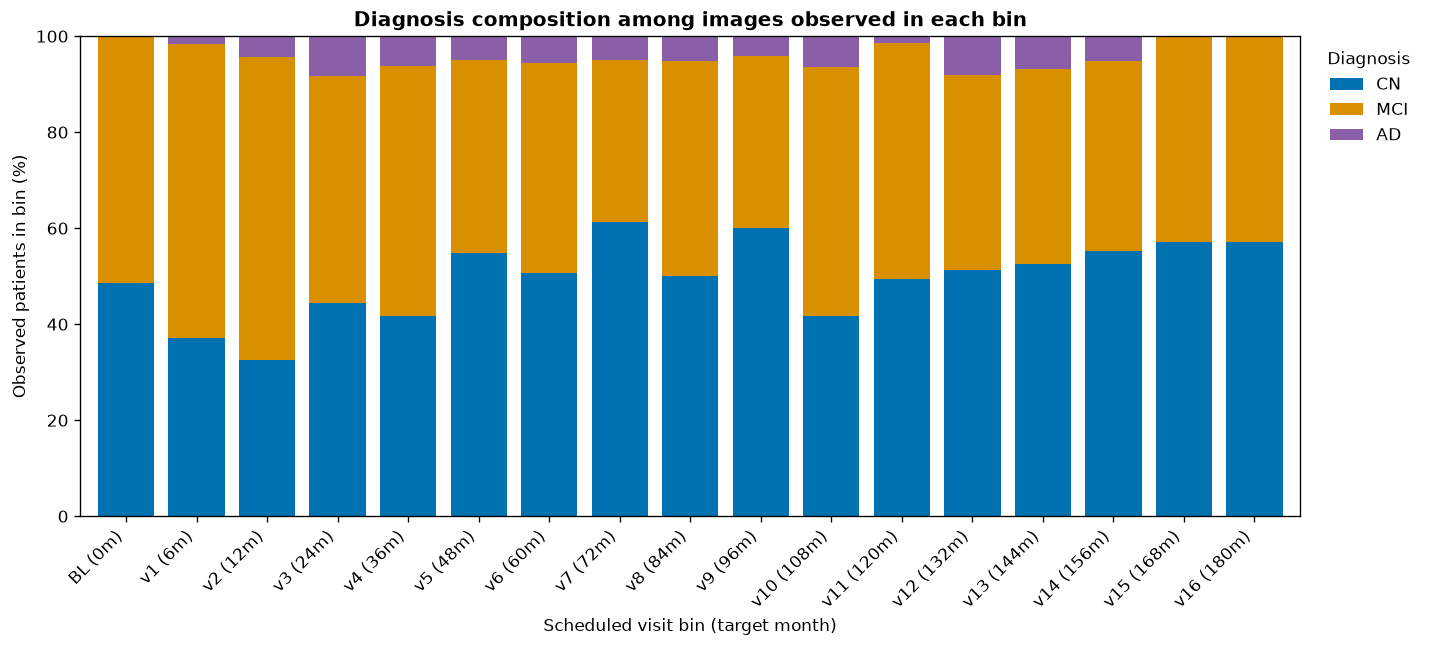

In [7]:
dx_counts = pd.crosstab(scan_df['visit_num'], scan_df['diagnosis_at_visit']).reindex(
    index=schedule.index, columns=['CN', 'MCI', 'AD'], fill_value=0)
dx_pct = dx_counts.div(dx_counts.sum(axis=1).replace(0, np.nan), axis=0).mul(100)
ax = dx_pct.set_axis(bin_labels).plot.bar(stacked=True, figsize=(12, 5.5),
    color=['#0072B2', '#D89000', '#8B5FA8'], width=0.8, rot=45)
ax.set(title='Diagnosis composition among images observed in each bin',
       xlabel='Scheduled visit bin (target month)', ylabel='Observed patients in bin (%)', ylim=(0, 100))
plt.setp(ax.get_xticklabels(), ha='right')
ax.legend(title='Diagnosis', frameon=False, bbox_to_anchor=(1.01, 1), loc='upper left')
ax.figure.tight_layout()
if SAVE_FIGURES:
    for extension in ['png', 'pdf']:
        ax.figure.savefig(FIGURE_DIR / f'diagnosis_by_bin.{extension}', bbox_inches='tight')
plt.show()

### Patient demographics

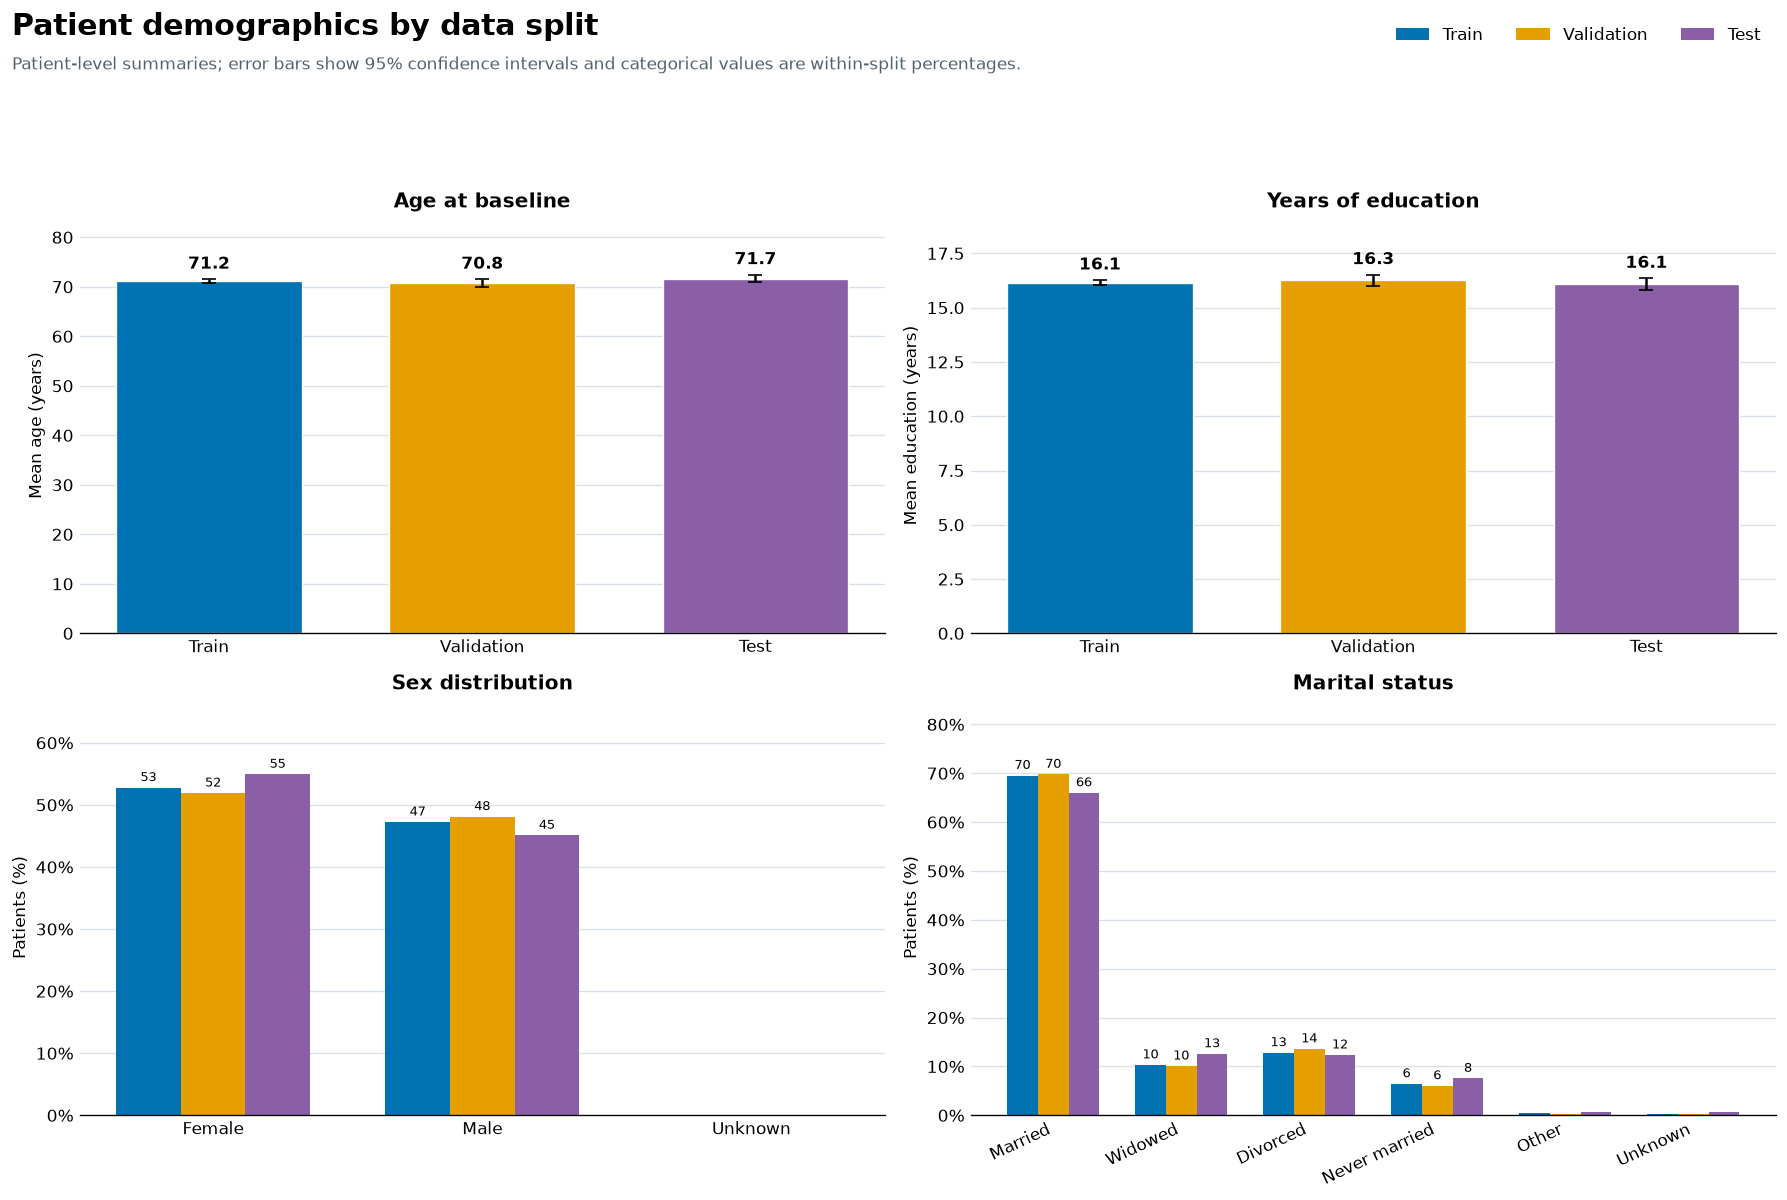

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
_mean_bars(axes[0, 0], patient_df, "age_at_baseline", "Age at baseline", "Mean age (years)")
_mean_bars(axes[0, 1], patient_df, "pt_education_years", "Years of education", "Mean education (years)")
_grouped_percent_bars(axes[1, 0], patient_df, "sex", ["Female", "Male", "Unknown"], "Sex distribution")
_grouped_percent_bars(
    axes[1, 1], patient_df, "marital_status",
    ["Married", "Widowed", "Divorced", "Never married", "Other", "Unknown"],
    "Marital status", rotate=25,
)
_finish_figure(
    fig, "Patient demographics by data split",
    "Patient-level summaries; error bars show 95% confidence intervals and categorical values are within-split percentages.",
    "patient_demographics_by_split",
)

### Diagnoses and disease progression

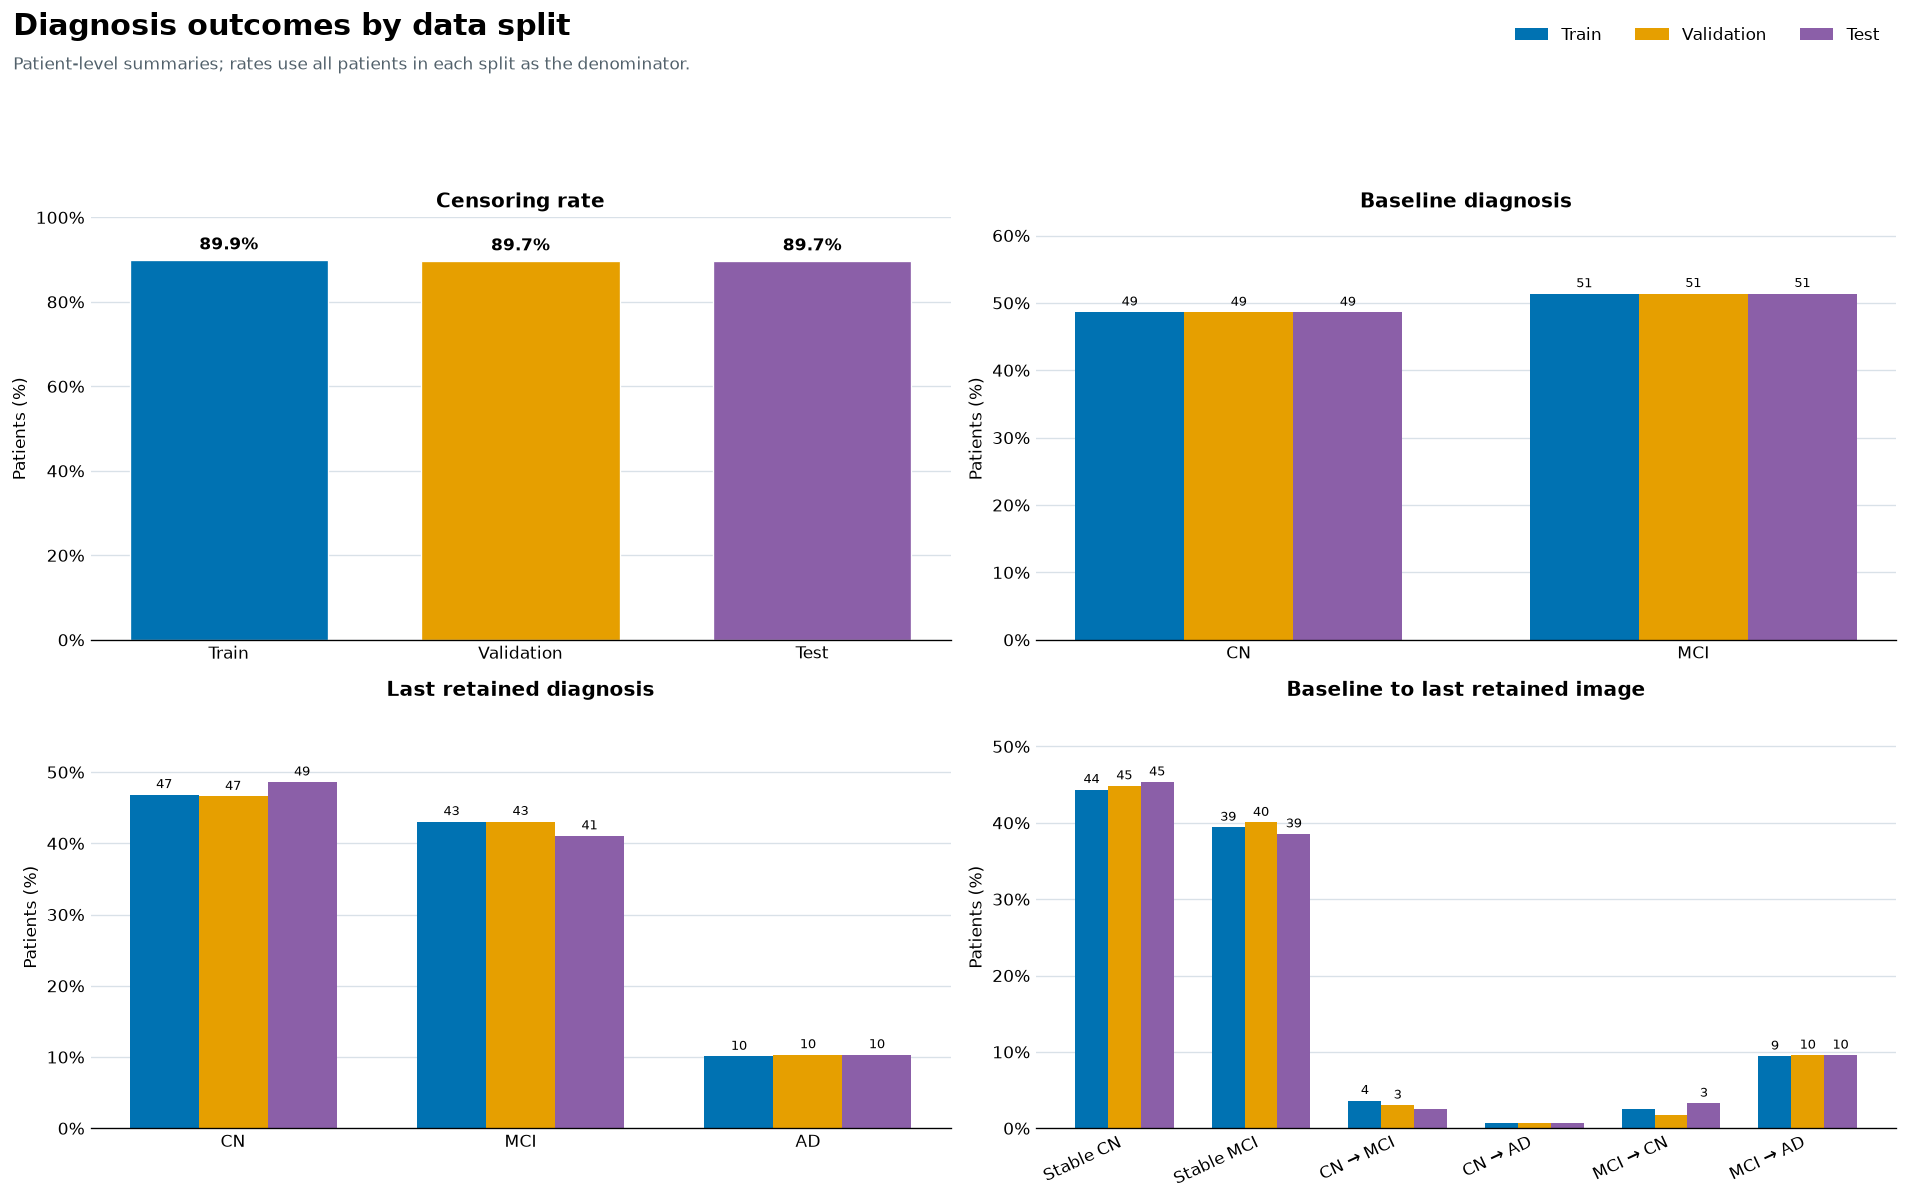

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
_rate_bars(axes[0, 0], patient_df, "is_censored", "Censoring rate")
_grouped_percent_bars(axes[0, 1], patient_df, "baseline_diagnosis", ["CN", "MCI"], "Baseline diagnosis")
_grouped_percent_bars(axes[1, 0], patient_df, "last_retained_diagnosis", ["CN", "MCI", "AD"], "Last retained diagnosis")
_grouped_percent_bars(
    axes[1, 1], patient_df, "diagnosis_change",
    ["Stable CN", "Stable MCI", "CN → MCI", "CN → AD", "MCI → CN", "MCI → AD"],
    "Baseline to last retained image", rotate=25,
)
_finish_figure(
    fig, "Diagnosis outcomes by data split",
    "Patient-level summaries; rates use all patients in each split as the denominator.",
    "diagnosis_outcomes_by_split",
)

### Scan metadata

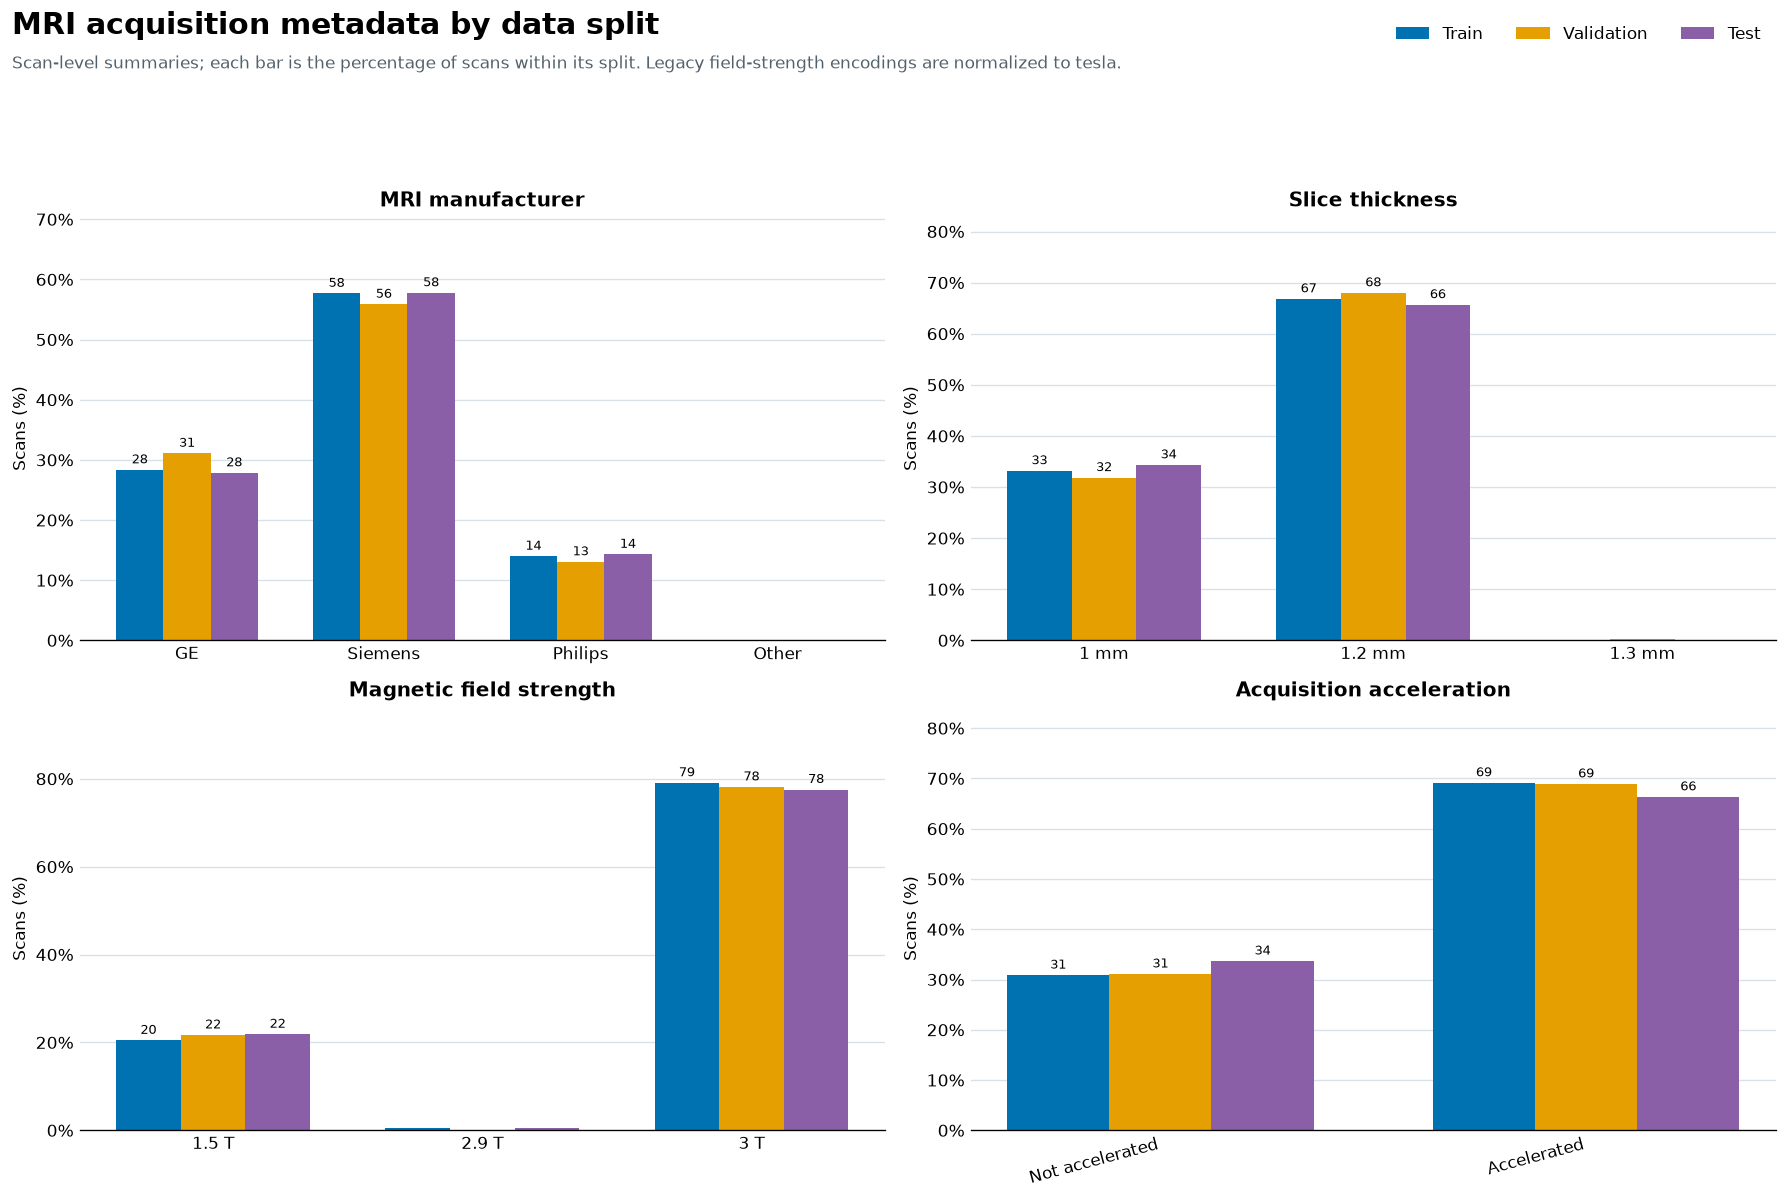

In [10]:
manufacturer_order = [name for name in ["GE", "Siemens", "Philips", "Other", "Unknown"] if name in scan_df["manufacturer"].unique()]
slice_order = [f"{value:g} mm" for value in sorted(slice_numeric.dropna().unique())]
field_order = [f"{value:g} T" for value in sorted(field_numeric.dropna().unique())]
acceleration_order = [name for name in ["Not accelerated", "Accelerated", "Unknown"] if name in scan_df["acceleration"].unique()]

# Preserve missing and previously unseen categories in every denominator.
manufacturer_order += sorted(set(scan_df['manufacturer']) - set(manufacturer_order))
if scan_df['slice_thickness_group'].eq('Unknown').any():
    slice_order.append('Unknown')
if scan_df['field_strength'].eq('Unknown').any():
    field_order.append('Unknown')

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
_grouped_percent_bars(axes[0, 0], scan_df, "manufacturer", manufacturer_order, "MRI manufacturer", unit="Scans")
_grouped_percent_bars(axes[0, 1], scan_df, "slice_thickness_group", slice_order, "Slice thickness", unit="Scans")
_grouped_percent_bars(axes[1, 0], scan_df, "field_strength", field_order, "Magnetic field strength", unit="Scans")
_grouped_percent_bars(axes[1, 1], scan_df, "acceleration", acceleration_order, "Acquisition acceleration", unit="Scans", rotate=15)
_finish_figure(
    fig, "MRI acquisition metadata by data split",
    "Scan-level summaries; each bar is the percentage of scans within its split. Legacy field-strength encodings are normalized to tesla.",
    "scan_metadata_by_split",
)

### Longitudinal follow-up distributions

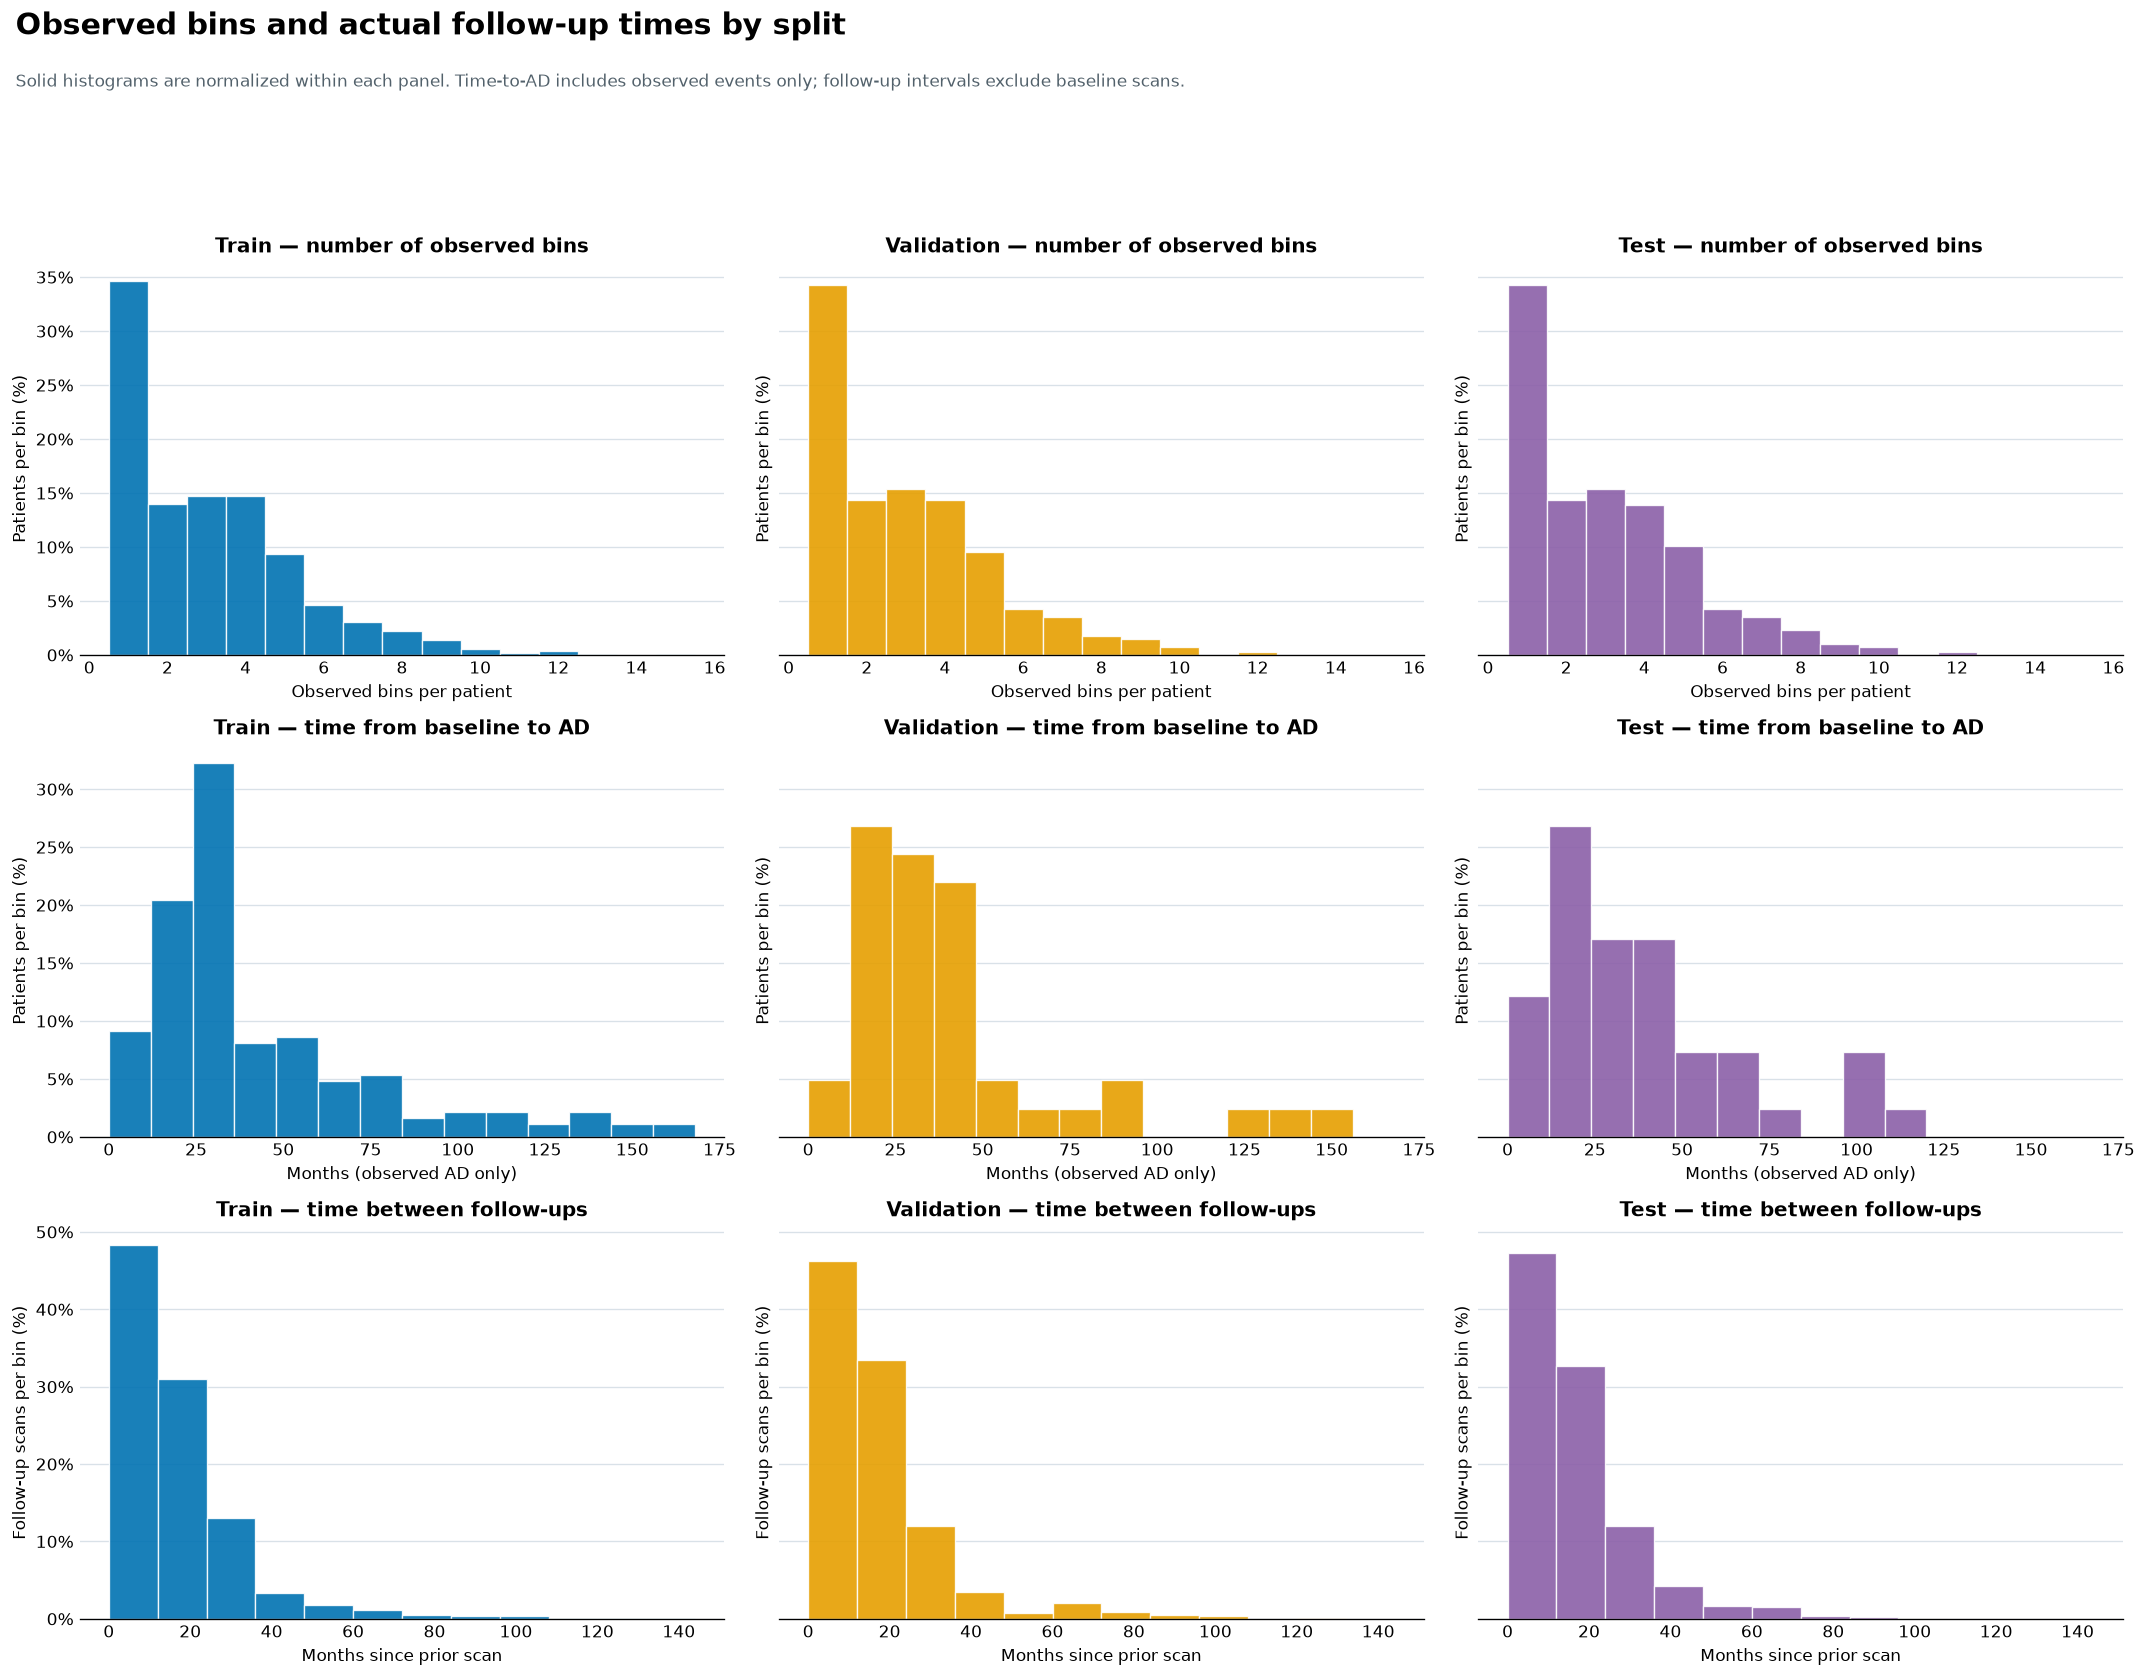

In [11]:
observed_ad_df = patient_df.loc[~patient_df["is_censored"]].copy()
followup_df = scan_df.loc[pd.to_numeric(scan_df["months_since_prior_image"], errors="coerce") > 0].copy()
max_visits = int(patient_df["n_visits"].max())
max_ad_months = float(pd.to_numeric(observed_ad_df["months_to_ad_from_baseline"], errors="coerce").max())
max_followup_months = float(pd.to_numeric(followup_df["months_since_prior_image"], errors="coerce").max())

max_ad_months = max_ad_months if np.isfinite(max_ad_months) and max_ad_months > 0 else 12
max_followup_months = max_followup_months if np.isfinite(max_followup_months) and max_followup_months > 0 else 12

visit_bins = np.arange(0.5, max_visits + 1.5, 1)
ad_bins = np.arange(0, np.ceil(max_ad_months / 12) * 12 + 12, 12)
followup_bins = np.arange(0, np.ceil(max_followup_months / 12) * 12 + 12, 12)

fig, axes = plt.subplots(3, 3, figsize=(18, 14), sharey="row")
for column_index, split in enumerate(SPLIT_ORDER):
    split_name = SPLIT_LABELS[split]
    _solid_histogram(
        axes[0, column_index], patient_df, "n_visits", visit_bins, split,
        f"{split_name} — number of observed bins", "Observed bins per patient",
    )
    axes[0, column_index].xaxis.set_major_locator(MaxNLocator(integer=True))
    _solid_histogram(
        axes[1, column_index], observed_ad_df, "months_to_ad_from_baseline", ad_bins, split,
        f"{split_name} — time from baseline to AD", "Months (observed AD only)",
    )
    _solid_histogram(
        axes[2, column_index], followup_df, "months_since_prior_image", followup_bins, split,
        f"{split_name} — time between follow-ups", "Months since prior scan", unit="Follow-up scans",
    )
_finish_figure(
    fig, "Observed bins and actual follow-up times by split",
    "Solid histograms are normalized within each panel. Time-to-AD includes observed events only; follow-up intervals exclude baseline scans.",
    "longitudinal_distributions_by_split",
    show_legend=False,
)

### Table 1. Cohort characteristics

Continuous baseline measures are reported as mean (SD), longitudinal measures as median [IQR], and categorical measures as n (%).

In [12]:
SAVE_TABLES = False
TABLE_DIR = Path(ROOT / "reports/tables")

group_keys = ["overall", *SPLIT_ORDER]
patient_group_sizes = {
    key: (len(patient_df) if key == "overall" else int((patient_df["split"] == key).sum()))
    for key in group_keys
}
column_labels = {
    "overall": f"Overall (N={patient_group_sizes['overall']:,})",
    **{key: f"{SPLIT_LABELS[key]} (N={patient_group_sizes[key]:,})" for key in SPLIT_ORDER},
}
table_rows = []

def _group_frame(data, group):
    return data if group == "overall" else data.loc[data["split"] == group]

def _mean_sd(values):
    values = pd.to_numeric(values, errors="coerce").dropna()
    return "—" if values.empty else f"{values.mean():.1f} ({values.std(ddof=1):.1f})"

def _median_iqr(values):
    values = pd.to_numeric(values, errors="coerce").dropna()
    if values.empty:
        return "—"
    q1, median, q3 = values.quantile([0.25, 0.50, 0.75])
    return f"{median:.1f} [{q1:.1f}, {q3:.1f}]"

def _n_percent(data, column, category):
    values = data[column].fillna("Unknown")
    count = int((values == category).sum())
    return "—" if len(data) == 0 else f"{count:,} ({100 * count / len(data):.1f}%)"

def _add_row(section, characteristic, level, formatter):
    row = {"Section": section, "Characteristic": characteristic, "Level": level}
    for group in group_keys:
        row[column_labels[group]] = formatter(group)
    table_rows.append(row)

def _add_categorical_rows(section, characteristic, data, column, categories):
    for category in categories:
        _add_row(
            section, characteristic, category,
            lambda group, category=category: _n_percent(_group_frame(data, group), column, category),
        )

_add_row("Patient demographics", "Patients, n", "", lambda group: f"{patient_group_sizes[group]:,}")
_add_row(
    "Patient demographics", "Age at baseline, years", "Mean (SD)",
    lambda group: _mean_sd(_group_frame(patient_df, group)["age_at_baseline"]),
)
_add_row(
    "Patient demographics", "Education, years", "Mean (SD)",
    lambda group: _mean_sd(_group_frame(patient_df, group)["pt_education_years"]),
)
_add_categorical_rows("Patient demographics", "Sex", patient_df, "sex", ["Female", "Male", "Unknown"])
_add_categorical_rows(
    "Patient demographics", "Marital status", patient_df, "marital_status",
    ["Married", "Widowed", "Divorced", "Never married", "Other", "Unknown"],
)

_add_categorical_rows("Diagnosis", "Censoring status", patient_df, "censor_status", ["Censored", "Observed AD"])
_add_categorical_rows("Diagnosis", "Baseline diagnosis", patient_df, "baseline_diagnosis", ["CN", "MCI"])
_add_categorical_rows("Diagnosis", "Last retained diagnosis", patient_df, "last_retained_diagnosis", ["CN", "MCI", "AD"])
_add_categorical_rows(
    "Diagnosis", "Baseline to last retained image", patient_df, "diagnosis_change",
    ["Stable CN", "Stable MCI", "CN → MCI", "CN → AD", "MCI → CN", "MCI → AD"],
)

_add_row(
    "Longitudinal follow-up", "Observed bins per patient", "Median [IQR]",
    lambda group: _median_iqr(_group_frame(patient_df, group)["n_visits"]),
)
_add_row(
    "Longitudinal follow-up", "Observed AD events, n", "",
    lambda group: f"{len(_group_frame(observed_ad_df, group)):,}",
)
_add_row(
    "Longitudinal follow-up", "Baseline to AD, months", "Median [IQR]",
    lambda group: _median_iqr(_group_frame(observed_ad_df, group)["months_to_ad_from_baseline"]),
)
_add_row(
    "Longitudinal follow-up", "Between follow-ups, months", "Median [IQR]",
    lambda group: _median_iqr(_group_frame(followup_df, group)["months_since_prior_image"]),
)

scan_group_sizes = {
    key: (len(scan_df) if key == "overall" else int((scan_df["split"] == key).sum()))
    for key in group_keys
}
_add_row("MRI acquisition", "Scans, n", "", lambda group: f"{scan_group_sizes[group]:,}")
_add_categorical_rows("MRI acquisition", "Manufacturer", scan_df, "manufacturer", manufacturer_order)
_add_categorical_rows("MRI acquisition", "Slice thickness", scan_df, "slice_thickness_group", slice_order)
_add_categorical_rows("MRI acquisition", "Field strength", scan_df, "field_strength", field_order)
_add_categorical_rows("MRI acquisition", "Acceleration", scan_df, "acceleration", acceleration_order)

table1 = pd.DataFrame(table_rows).set_index(["Section", "Characteristic", "Level"])
table1.index.names = [None, None, None]
table1_styled = (
    table1.style
    .set_caption("Table 1. Cohort demographic, clinical, longitudinal, and MRI acquisition characteristics")
    .set_table_styles([
        {"selector": "caption", "props": [("caption-side", "top"), ("font-size", "16px"), ("font-weight", "bold"), ("text-align", "left"), ("padding", "8px 0")]},
        {"selector": "th", "props": [("background-color", "#EAF1F5"), ("font-weight", "bold"), ("border-bottom", "1px solid #AAB7C2"), ("padding", "6px 10px")]},
        {"selector": "td", "props": [("border-bottom", "1px solid #E3E8EC"), ("padding", "5px 10px")]},
    ])
    .set_properties(**{"text-align": "right"})
)

if SAVE_TABLES:
    TABLE_DIR.mkdir(parents=True, exist_ok=True)
    table1.to_csv(TABLE_DIR / "table_1_cohort_characteristics.csv")
    table1.to_latex(TABLE_DIR / "table_1_cohort_characteristics.tex", escape=True)
    (TABLE_DIR / "table_1_cohort_characteristics.html").write_text(table1_styled.to_html(), encoding="utf-8")

table1_styled

**Notes.** Percentages use the column-specific denominator. Demographic, diagnosis, and observed-bin-count rows use patients; MRI acquisition rows use scans; time-between-follow-up rows use non-baseline scans. Time-to-AD summaries include observed AD events only. CN = cognitively normal; MCI = mild cognitive impairment; AD = Alzheimer’s disease; SD = standard deviation; IQR = interquartile range.

## Takeaways
The displayed tables and charts describe the saved split cohort, with consistent patient
and image denominators. Baseline-relative coverage is sparse at late visits; comparisons
at those bins involve selected subsets, not the original cohort at a common risk time.
`v1` can include scans only days after BL, as specified by the current schedule. Use actual
acquisition months for prediction-time cutoffs, not the bin's nominal target month.

In [13]:
display(Markdown(
    f"This split includes **{len(patient_df):,} patients** and **{len(scan_df):,} images**. "
    f"**{int((~patient_df['is_censored']).sum()):,}** patients have an observed AD event; "
    f"**{int((patient_df['n_visits'] == 1).sum()):,}** have only baseline retained. "
    f"The last scheduled bin contains **{int(bin_counts.iloc[-1].sum()):,}** images. "
    "Tensor-file existence was checked at split creation; tensor content alignment remains a separate training check."
))

This split includes **2,636 patients** and **8,027 images**. **268** patients have an observed AD event; **910** have only baseline retained. The last scheduled bin contains **7** images. Tensor-file existence was checked at split creation; tensor content alignment remains a separate training check.

## Historical experiment results (optional)
Set `SHOW_EXPERIMENT_RESULTS = True` to enable the existing experiment diagnostics.
`EXPERIMENT_RUN_ID = None` selects the latest completed unified or legacy run; an explicit
run UUID can select a partial run. These saved experiments may use the **old cohort/split**.
The notebook reports assignment overlap but does not relabel old results as new-bin evaluations.

In [14]:
SHOW_EXPERIMENT_RESULTS = False
import pandas as pd
# Configuration: use None for the latest completed run, or paste a run UUID.
EXPERIMENT_RUN_ID: str | None = None

EXPERIMENT_STORES = {
    "survival": {
        "label": "Unified baseline/LTSA",
        "runs": "survival_runs",
        "epochs": "survival_epoch_metrics",
        "patients": "survival_run_patients",
        "predictions": "survival_test_predictions",
        "train_loss": "train_total_loss",
        "validation_loss": "validation_total_loss",
    },
    "legacy_baseline": {
        "label": "Legacy baseline",
        "runs": "baseline_runs",
        "epochs": "baseline_epoch_metrics",
        "patients": "baseline_run_patients",
        "predictions": "baseline_test_predictions",
        "train_loss": "train_loss",
        "validation_loss": "validation_loss",
    },
}


def _read_experiment_table(connection, query, parameters=None):
    return pd.read_sql_query(
        sqlalchemy.text(query),
        connection,
        params=parameters or {},
    )


def load_experiment_run(engine, run_id=None):
    """Load one experiment and normalize legacy and unified result columns."""
    with engine.connect() as connection:
        inspector = sqlalchemy.inspect(connection)
        available_stores = {
            key: store
            for key, store in EXPERIMENT_STORES.items()
            if inspector.has_table(store["runs"], schema="_ml")
        }
        if not available_stores:
            raise RuntimeError("No experiment result tables were found in the _ml schema.")

        candidates = []
        for store_key, store in available_stores.items():
            if run_id is None:
                where_clause = "status = 'completed'"
                parameters = {}
            else:
                where_clause = "run_id::text = :run_id"
                parameters = {"run_id": run_id}

            candidate = _read_experiment_table(
                connection,
                f"""
                SELECT *
                FROM _ml.{store['runs']}
                WHERE {where_clause}
                ORDER BY completed_at DESC NULLS LAST, started_at DESC
                LIMIT 1
                """,
                parameters,
            )
            if not candidate.empty:
                candidate["_store_key"] = store_key
                candidate["_store_label"] = store["label"]
                candidates.append(candidate)

        if not candidates:
            if run_id is None:
                raise RuntimeError("No completed experiment runs were found.")
            raise ValueError(f"Experiment run {run_id!r} was not found.")

        candidate_runs = pd.concat(candidates, ignore_index=True)
        candidate_runs["_sort_time"] = pd.to_datetime(
            candidate_runs["completed_at"].fillna(candidate_runs["started_at"]),
            utc=True,
            errors="coerce",
        )
        selected_run = (
            candidate_runs.sort_values("_sort_time", ascending=False)
            .iloc[0]
            .to_dict()
        )
        selected_store = available_stores[selected_run["_store_key"]]
        selected_run_id = str(selected_run["run_id"])
        parameters = {"run_id": selected_run_id}

        epoch_metrics = _read_experiment_table(
            connection,
            f"""
            SELECT
                epoch,
                {selected_store['train_loss']} AS train_loss,
                train_c_index,
                {selected_store['validation_loss']} AS validation_loss,
                validation_c_index,
                learning_rate
            FROM _ml.{selected_store['epochs']}
            WHERE run_id::text = :run_id
            ORDER BY epoch
            """,
            parameters,
        )
        patients = _read_experiment_table(
            connection,
            f"""
            SELECT ptid, split, observed_time_months, event_observed
            FROM _ml.{selected_store['patients']}
            WHERE run_id::text = :run_id
            """,
            parameters,
        )
        predictions = _read_experiment_table(
            connection,
            f"""
            SELECT ptid, observed_time_months, event_observed, risk_score
            FROM _ml.{selected_store['predictions']}
            WHERE run_id::text = :run_id
            """,
            parameters,
        )

        comparison_runs = pd.DataFrame()
        if selected_run["_store_key"] == "survival":
            comparison_runs = _read_experiment_table(
                connection,
                """
                SELECT
                    run_id::text AS run_id,
                    model_type,
                    landmark_months,
                    status,
                    test_c_index,
                    paired_c_index_difference,
                    paired_ci_low,
                    paired_ci_high
                FROM _ml.survival_runs
                WHERE comparison_id = :comparison_id
                  AND landmark_months = :landmark_months
                ORDER BY model_type
                """,
                {
                    "comparison_id": str(selected_run["comparison_id"]),
                    "landmark_months": selected_run["landmark_months"],
                },
            )

    return selected_run, epoch_metrics, patients, predictions, comparison_runs



experiment_run = None
if SHOW_EXPERIMENT_RESULTS:
    (
        experiment_run,
        experiment_epoch_df,
        experiment_patient_df,
        experiment_prediction_df,
        experiment_comparison_df,
    ) = load_experiment_run(get_db_engine(), EXPERIMENT_RUN_ID)
else:
    display(Markdown("Historical experiment diagnostics are disabled."))

Historical experiment diagnostics are disabled.

### Selected run

The summary identifies the resolved run before plotting. Unified runs also show any matched baseline/LTSA rows at the same comparison and landmark.

In [15]:
if experiment_run is not None:
    def _format_experiment_timestamp(value):
        if value is None or pd.isna(value):
            return "—"
        return pd.Timestamp(value).strftime("%Y-%m-%d %H:%M:%S %Z")


    def _format_experiment_metric(value, digits=4):
        if value is None or pd.isna(value):
            return "—"
        return f"{float(value):.{digits}f}"


    experiment_model = experiment_run.get("model_type")
    if experiment_model is None or pd.isna(experiment_model):
        experiment_model = "baseline (legacy)"

    landmark_months = experiment_run.get("landmark_months")
    landmark_label = (
        "—"
        if landmark_months is None or pd.isna(landmark_months)
        else f"{float(landmark_months):g}"
    )
    best_epoch = experiment_run.get("best_epoch")
    best_epoch_label = "—" if best_epoch is None or pd.isna(best_epoch) else f"{int(best_epoch)}"

    experiment_summary = pd.DataFrame.from_dict(
        {
            "Result store": experiment_run["_store_label"],
            "Run ID": str(experiment_run["run_id"]),
            "Model": str(experiment_model),
            "Landmark (months)": landmark_label,
            "Status": experiment_run["status"],
            "Started": _format_experiment_timestamp(experiment_run.get("started_at")),
            "Completed": _format_experiment_timestamp(experiment_run.get("completed_at")),
            "Best epoch": best_epoch_label,
            "Best validation loss": _format_experiment_metric(
                experiment_run.get("best_validation_loss")
            ),
            "Best validation C-index": _format_experiment_metric(
                experiment_run.get("best_validation_c_index")
            ),
            "Test C-index": _format_experiment_metric(experiment_run.get("test_c_index")),
            "Cohort (train / validation / test)": " / ".join(
                f"{int(experiment_run.get(f'{split}_patients', 0)):,}"
                for split in SPLIT_ORDER
            ),
        },
        orient="index",
        columns=["Value"],
    )
    display(experiment_summary)

    if not experiment_comparison_df.empty:
        display(
            experiment_comparison_df.rename(
                columns={
                    "run_id": "Run ID",
                    "model_type": "Model",
                    "landmark_months": "Landmark (months)",
                    "status": "Status",
                    "test_c_index": "Test C-index",
                    "paired_c_index_difference": "LTSA − baseline",
                    "paired_ci_low": "95% CI low",
                    "paired_ci_high": "95% CI high",
                }
            )
        )
    current_assignment = assignments.to_pandas().rename(columns={'split': 'current_split'})
    overlap = experiment_patient_df.merge(current_assignment, on='ptid', how='left', validate='many_to_one')
    changed = int((overlap['split'] != overlap['current_split']).sum())
    display(Markdown(f'**Historical cohort check:** {changed:,} run patients have a different or absent current assignment. '
                     'Agreement alone does not verify that the run used the current selected image IDs.'))


### Run diagnostics

Learning curves show optimization and discrimination by epoch. Cohort counts retain the event denominator for each split, and the test-set panel relates predicted risk to observed follow-up. The dashed line marks the checkpoint selected during training.

In [16]:
if experiment_run is not None:
    EXPERIMENT_COLORS = {
        "train": "#0072B2",
        "validation": "#E69F00",
        "event": "#0072B2",
        "censored": "#E69F00",
    }

    fig, axes = plt.subplots(2, 2, figsize=(16, 11))
    loss_axis, c_index_axis, cohort_axis, prediction_axis = axes.flat

    if experiment_epoch_df.empty:
        for axis in (loss_axis, c_index_axis):
            axis.text(
                0.5,
                0.5,
                "No epoch metrics recorded",
                ha="center",
                va="center",
                transform=axis.transAxes,
            )
    else:
        for column, label, color in (
            ("train_loss", "Train", EXPERIMENT_COLORS["train"]),
            ("validation_loss", "Validation", EXPERIMENT_COLORS["validation"]),
        ):
            loss_axis.plot(
                experiment_epoch_df["epoch"],
                experiment_epoch_df[column],
                marker="o",
                markersize=4,
                linewidth=2,
                label=label,
                color=color,
            )

        for column, label, color in (
            ("train_c_index", "Train", EXPERIMENT_COLORS["train"]),
            ("validation_c_index", "Validation", EXPERIMENT_COLORS["validation"]),
        ):
            values = pd.to_numeric(experiment_epoch_df[column], errors="coerce")
            if values.notna().any():
                c_index_axis.plot(
                    experiment_epoch_df["epoch"],
                    values,
                    marker="o",
                    markersize=4,
                    linewidth=2,
                    label=label,
                    color=color,
                )

        if best_epoch is not None and pd.notna(best_epoch):
            for axis in (loss_axis, c_index_axis):
                axis.axvline(
                    best_epoch,
                    color="#3B4651",
                    linestyle="--",
                    linewidth=1.2,
                    label="Selected epoch",
                )

        loss_axis.legend(frameon=False)
        c_index_axis.legend(frameon=False)

    loss_axis.set(title="Training and validation loss", xlabel="Epoch", ylabel="Loss")
    c_index_axis.set(
        title="Training and validation concordance",
        xlabel="Epoch",
        ylabel="Harrell C-index",
        ylim=(0, 1),
    )

    if experiment_patient_df.empty:
        cohort_axis.text(
            0.5,
            0.5,
            "No cohort rows recorded",
            ha="center",
            va="center",
            transform=cohort_axis.transAxes,
        )
    else:
        patient_outcomes = experiment_patient_df.assign(
            outcome=np.where(
                experiment_patient_df["event_observed"].fillna(False).astype(bool),
                "Observed event",
                "Censored",
            )
        )
        available_splits = patient_outcomes["split"].dropna().unique().tolist()
        experiment_split_order = [
            split for split in SPLIT_ORDER if split in available_splits
        ]
        experiment_split_order += sorted(
            set(available_splits) - set(experiment_split_order)
        )
        cohort_counts = (
            patient_outcomes.groupby(["split", "outcome"], observed=True)
            .size()
            .unstack(fill_value=0)
            .reindex(
                index=experiment_split_order,
                columns=["Observed event", "Censored"],
                fill_value=0,
            )
        )
        bottoms = np.zeros(len(cohort_counts))
        for outcome, color in (
            ("Observed event", EXPERIMENT_COLORS["event"]),
            ("Censored", EXPERIMENT_COLORS["censored"]),
        ):
            bars = cohort_axis.bar(
                cohort_counts.index,
                cohort_counts[outcome],
                bottom=bottoms,
                label=outcome,
                color=color,
                edgecolor="white",
            )
            labels = [f"{int(value):,}" if value else "" for value in cohort_counts[outcome]]
            cohort_axis.bar_label(
                bars,
                labels=labels,
                label_type="center",
                color="white",
                fontweight="bold",
            )
            bottoms += cohort_counts[outcome].to_numpy()
        cohort_axis.legend(frameon=False)

    cohort_axis.set(title="Cohort outcomes by split", xlabel="Split", ylabel="Patients")

    if experiment_prediction_df.empty:
        prediction_axis.text(
            0.5,
            0.5,
            "No test predictions recorded",
            ha="center",
            va="center",
            transform=prediction_axis.transAxes,
        )
    else:
        observed_predictions = (
            experiment_prediction_df["event_observed"].fillna(False).astype(bool)
        )
        prediction_axis.scatter(
            experiment_prediction_df.loc[observed_predictions, "observed_time_months"],
            experiment_prediction_df.loc[observed_predictions, "risk_score"],
            s=35,
            alpha=0.75,
            color=EXPERIMENT_COLORS["event"],
            label="Observed event",
        )
        prediction_axis.scatter(
            experiment_prediction_df.loc[~observed_predictions, "observed_time_months"],
            experiment_prediction_df.loc[~observed_predictions, "risk_score"],
            s=35,
            alpha=0.8,
            facecolors="white",
            edgecolors=EXPERIMENT_COLORS["censored"],
            linewidth=1.2,
            label="Censored",
        )
        prediction_axis.legend(frameon=False)

    prediction_axis.set(
        title="Test-set risk scores and follow-up",
        xlabel="Observed time (months)",
        ylabel="Predicted risk score",
    )

    for axis in axes.flat:
        axis.spines[["top", "right"]].set_visible(False)
        axis.grid(color="#D9E1E8", linewidth=0.8, alpha=0.8)
        axis.set_axisbelow(True)

    experiment_run_id = str(experiment_run["run_id"])
    figure_subtitle = (
        f"{experiment_model} | run {experiment_run_id} | "
        f"status: {experiment_run['status']} | "
        f"test predictions: {len(experiment_prediction_df):,}"
    )
    fig.suptitle(
        "Experiment diagnostics",
        x=0.01,
        y=0.995,
        ha="left",
        fontsize=18,
        fontweight="bold",
    )
    fig.text(
        0.01,
        0.958,
        figure_subtitle,
        ha="left",
        va="top",
        fontsize=10,
        color="#52616B",
    )
    fig.tight_layout(rect=(0, 0, 1, 0.91))

    if SAVE_FIGURES:
        FIGURE_DIR.mkdir(parents=True, exist_ok=True)
        experiment_figure_name = f"experiment_diagnostics_{experiment_run_id[:8]}"
        fig.savefig(
            FIGURE_DIR / f"{experiment_figure_name}.png",
            bbox_inches="tight",
            facecolor="white",
        )
        fig.savefig(
            FIGURE_DIR / f"{experiment_figure_name}.pdf",
            bbox_inches="tight",
            facecolor="white",
        )

    plt.show()